In [25]:
!pip install numpy
!pip install pandas
!pip install matplotlib seaborn

In [26]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
df=pd.read_csv('/content/train - train.csv')

In [28]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [29]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [30]:
df.shape

(891, 12)

In [31]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [32]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [33]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [35]:
missing=df.isnull().sum()
print("Missing",missing)

Missing PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


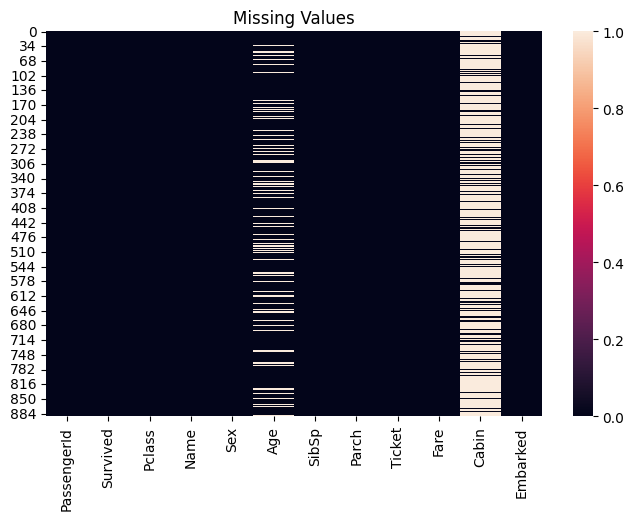

In [36]:
plt.figure(figsize=(8,5))
sns.heatmap(df.isnull(),cbar=True)
plt.title("Missing Values")
plt.show()

In [37]:
num=df.select_dtypes(include=['int64','float64']).columns
print("NUMERICAL COLUMNS",list(num))
cat=df.select_dtypes(include=['object','category']).columns
print("CATEGORICAL COLUMNS",list(cat))

NUMERICAL COLUMNS ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
CATEGORICAL COLUMNS ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


In [38]:
for col in df.columns:
  print(col,":",df[col].nunique(),"Unique values")
  if df[col].nunique() < 10:
    print(df[col].unique())

PassengerId : 891 Unique values
Survived : 2 Unique values
[0 1]
Pclass : 3 Unique values
[3 1 2]
Name : 891 Unique values
Sex : 2 Unique values
['male' 'female']
Age : 88 Unique values
SibSp : 7 Unique values
[1 0 3 4 2 5 8]
Parch : 7 Unique values
[0 1 2 5 3 4 6]
Ticket : 681 Unique values
Fare : 248 Unique values
Cabin : 147 Unique values
Embarked : 3 Unique values
['S' 'C' 'Q' nan]


In [39]:
# Missing values before handling
print(df[['Age','Cabin','Embarked']].isnull().sum())

Age         177
Cabin       687
Embarked      2
dtype: int64


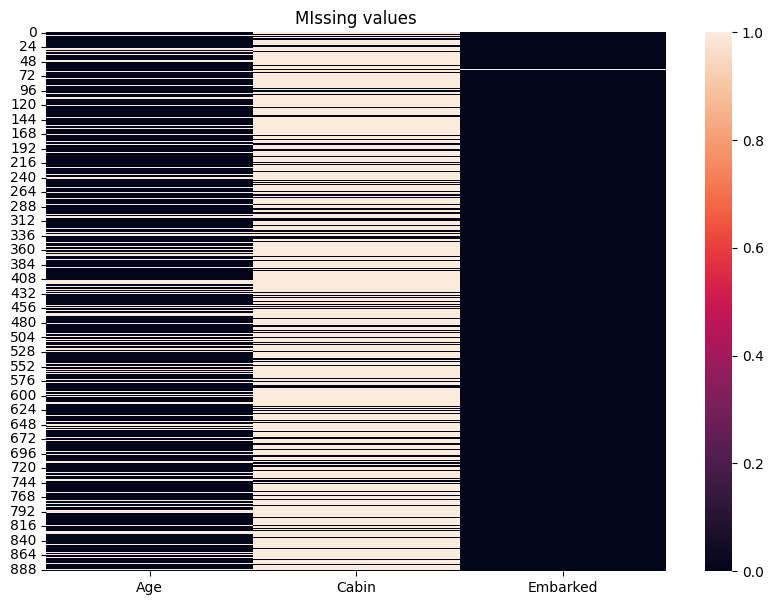

In [40]:
# Visualize missing values
plt.figure(figsize=(10,7))
sns.heatmap(df[['Age','Cabin','Embarked']].isnull())
plt.title("MIssing values")
plt.show()

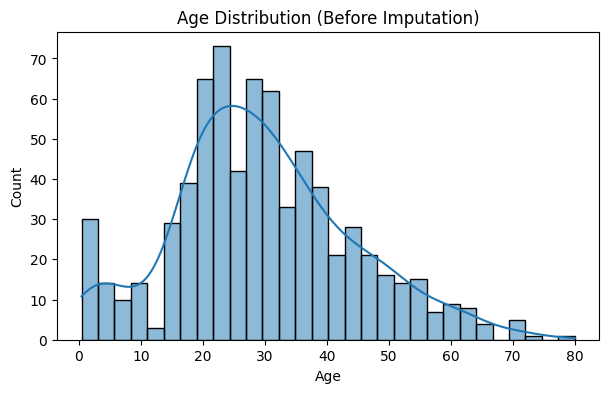

Skewness of Age: 0.38910778230082704


In [41]:
plt.figure(figsize=(7,4))
sns.histplot(df['Age'],bins=30, kde=True) # kde=True adds a smooth curve (Kernel Density Estimate) to show the data distribution shape.
plt.title("Age Distribution (Before Imputation)")
plt.show()
print("Skewness of Age:", df['Age'].skew())

In [42]:
df['Cabin'].head()

,Cabin
0,NaN
1,C85
2,NaN
3,C123
4,NaN


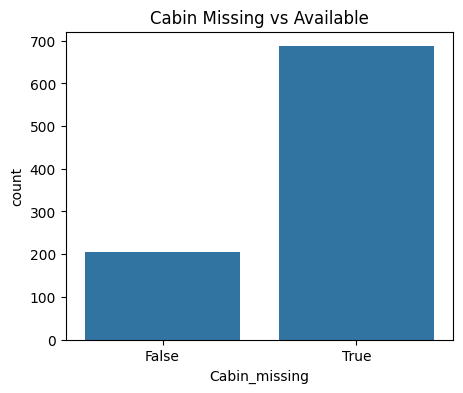

In [43]:
plt.figure(figsize=(5,4))
df['Cabin_missing'] = df['Cabin'].isnull()
sns.countplot(x='Cabin_missing', data=df)
plt.title("Cabin Missing vs Available")
plt.show()

In [44]:
df['Cabin_missing'].head()

,Cabin_missing
0,True
1,False
2,True
3,False
4,True


In [45]:
# Age → fill with group median
df['Age']=df.groupby(['Sex','Pclass'])['Age'].transform(lambda x:x.fillna(x.median()))

In [46]:
# Embarked → fill with mode
df['Embarked'].fillna(df['Embarked'].mode()[0],inplace=True)

/tmp/ipykernel_1590/4277886025.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Embarked'].fillna(df['Embarked'].mode()[0],inplace=True)


In [47]:
# Cabin → extract Deck
df['Deck']=df['Cabin'].apply(lambda x:x[0] if pd.notnull(x) else 'unknown')

In [48]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Cabin_missing,Deck
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,True,unknown
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,False,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,True,unknown
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,False,C
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,True,unknown


In [49]:
m=df.isnull().sum()
print(m)

PassengerId        0
Survived           0
Pclass             0
Name               0
Sex                0
Age                0
SibSp              0
Parch              0
Ticket             0
Fare               0
Cabin            687
Embarked           0
Cabin_missing      0
Deck               0
dtype: int64


# Anaylsis After Handling Missing Values

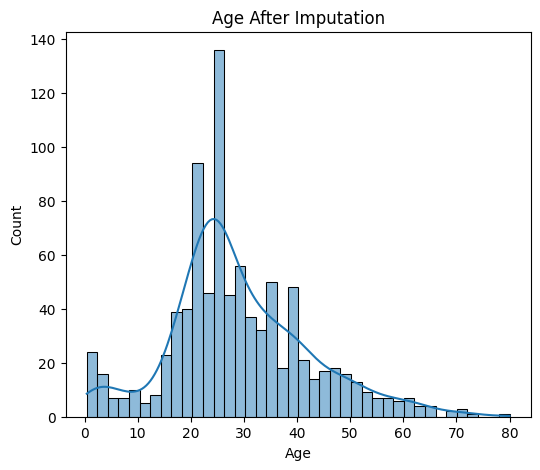

In [50]:
from pandas.core.reshape import tile
plt.figure(figsize=(6,5))
sns.histplot(df['Age'],bins=40,kde=True)
plt.title("Age After Imputation")
plt.show()

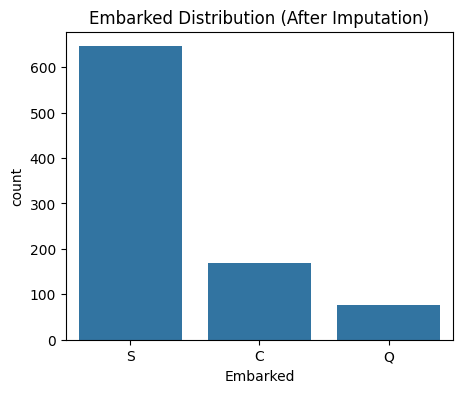

In [51]:
plt.figure(figsize=(5,4))
sns.countplot(x='Embarked', data=df)
plt.title("Embarked Distribution (After Imputation)")
plt.show()

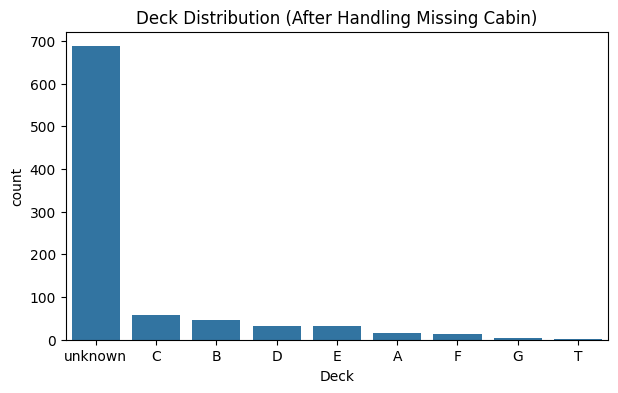

In [52]:
plt.figure(figsize=(7,4))
sns.countplot(x='Deck', data=df, order=df['Deck'].value_counts().index)
plt.title("Deck Distribution (After Handling Missing Cabin)")
plt.show()

In [53]:
#Family size & is alone
if set(['SibSp','Parch']).issubset(df.columns):
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

In [54]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Cabin_missing,Deck,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,True,unknown,2,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,False,C,2,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,True,unknown,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,False,C,2,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,True,unknown,1,1


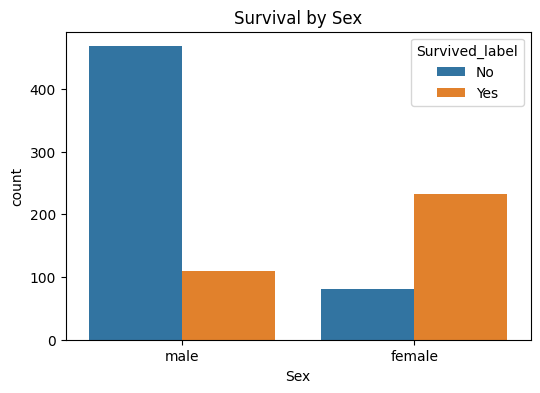

In [55]:
if set(['Sex','Survived']).issubset(df.columns):
    df['Survived_label'] = df['Survived'].map({0:'No', 1:'Yes'})
    plt.figure(figsize=(6,4))
    sns.countplot(x='Sex', hue='Survived_label', data=df)
    plt.title('Survival by Sex')
    plt.show()

/tmp/ipykernel_1590/1368371737.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Pclass', y='Survived', data=df, estimator=np.mean, ci=None)


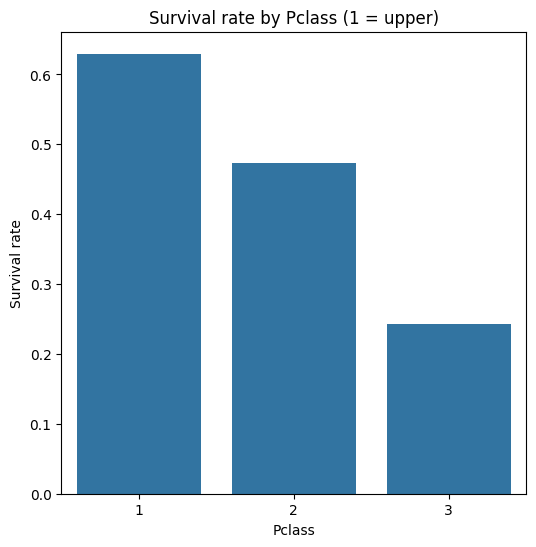

In [56]:
if set(['Pclass','Survived']).issubset(df.columns):
  plt.figure(figsize=(6,6))
  sns.barplot(x='Pclass', y='Survived', data=df, estimator=np.mean, ci=None)
  plt.title('Survival rate by Pclass (1 = upper)')
  plt.ylabel('Survival rate')
  plt.show()

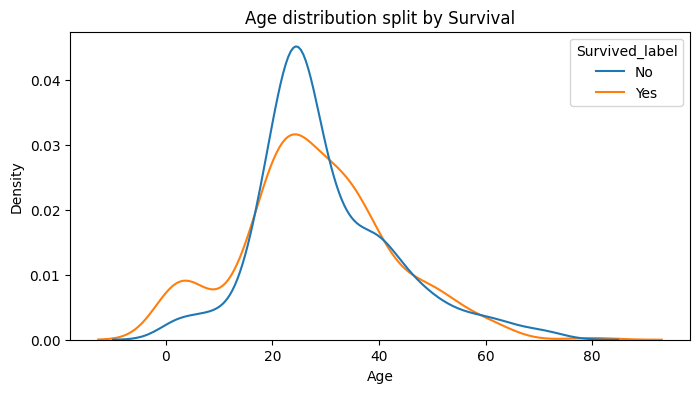

In [57]:
if 'Age' in df.columns:
    plt.figure(figsize=(8,4))
    sns.kdeplot(data=df, x='Age', hue='Survived_label', common_norm=False)
    plt.title('Age distribution split by Survival')
    plt.show()

/tmp/ipykernel_1590/920062769.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Embarked', y='Survived', data=df, estimator=np.mean, ci=None)


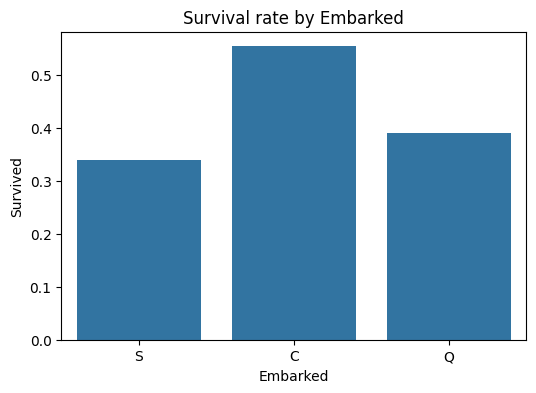

In [58]:
if set(['Embarked','Survived']).issubset(df.columns):
    plt.figure(figsize=(6,4))
    sns.barplot(x='Embarked', y='Survived', data=df, estimator=np.mean, ci=None)
    plt.title('Survival rate by Embarked')
    plt.show()

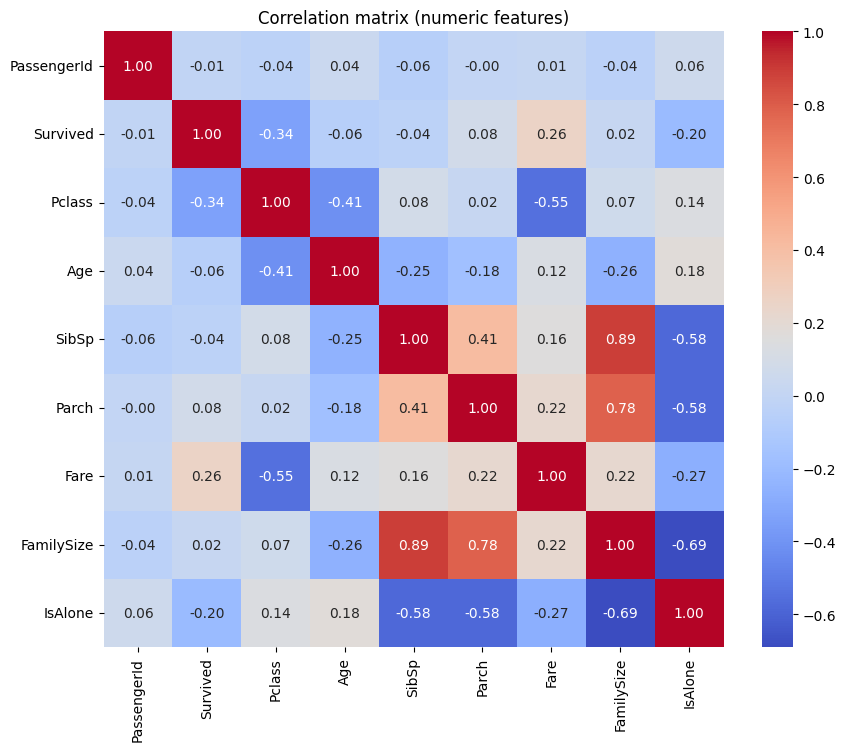

In [59]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
plt.figure(figsize=(10,8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation matrix (numeric features)')
plt.show()

Analysis Questions

How does survival differ between males and females?

How does passenger class (Pclass) affect survival?

Does age (children vs adults vs seniors) affect survival probability?

Is Fare (a proxy for wealth/class) associated with higher survival?

Does family size (alone vs small family vs large family) influence survival?

In [60]:
# Q1: Does sex affect survival?
if 'Sex' in df.columns:
    survival_by_sex = df.groupby('Sex')['Survived'].mean().sort_values(ascending=False)
    print("Q1 - Survival rate by Sex:\n", survival_by_sex)

Q1 - Survival rate by Sex:
 Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


In [61]:
# Q2: How does passenger class affect survival?
if 'Pclass' in df.columns:
    survival_by_class = df.groupby('Pclass')['Survived'].mean().sort_values(ascending=False)
    print("\nQ2 - Survival rate by Pclass:\n", survival_by_class)


Q2 - Survival rate by Pclass:
 Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


In [62]:
# Q3: How does age affect survival? (binned)
if 'Age' in df.columns:
    bins = [0, 12, 18, 35, 60, 120]
    labels = ['Child','Teen','YoungAdult','Adult','Senior']
    df['AgeGroup'] = pd.cut(df['Age'], bins=bins, labels=labels)
    print("\nQ3 - Survival rate by AgeGroup:\n", df.groupby('AgeGroup')['Survived'].mean())


Q3 - Survival rate by AgeGroup:
 AgeGroup
Child         0.579710
Teen          0.428571
YoungAdult    0.357977
Adult         0.384259
Senior        0.227273
Name: Survived, dtype: float64


/tmp/ipykernel_1590/2640693220.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print("\nQ3 - Survival rate by AgeGroup:\n", df.groupby('AgeGroup')['Survived'].mean())


In [63]:
# Q5: Does family size or being alone affect survival?
if 'FamilySize' in df.columns:
    print("\nQ5 - Survival rate by FamilySize (small sample):")
    display(df.groupby('FamilySize')['Survived'].mean().sort_index())
    print("\nSurvival rate when IsAlone = 1 vs 0:")
    display(df.groupby('IsAlone')['Survived'].mean())


Q5 - Survival rate by FamilySize (small sample):


,Survived
FamilySize,
1,0.303538
2,0.552795
3,0.578431
4,0.724138
5,0.200000
6,0.136364
7,0.333333
8,0.000000
11,0.000000



Survival rate when IsAlone = 1 vs 0:


,Survived
IsAlone,
0,0.505650
1,0.303538


The port of embarkation affect survival


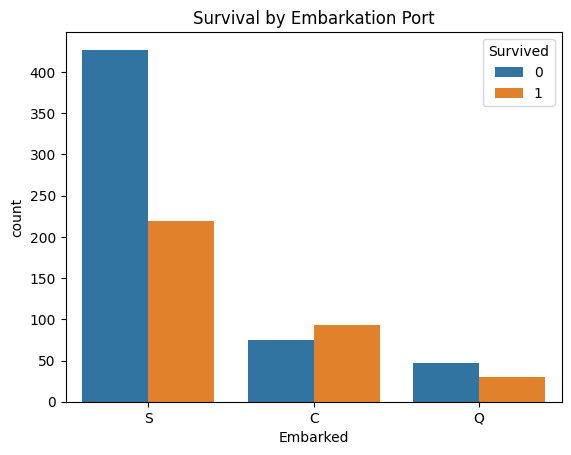

In [64]:
# Q6 : Does the port of embarkation affect survival?
print("The port of embarkation affect survival")
sns.countplot(x='Embarked', hue='Survived', data=df)
plt.title('Survival by Embarkation Port')
plt.show()

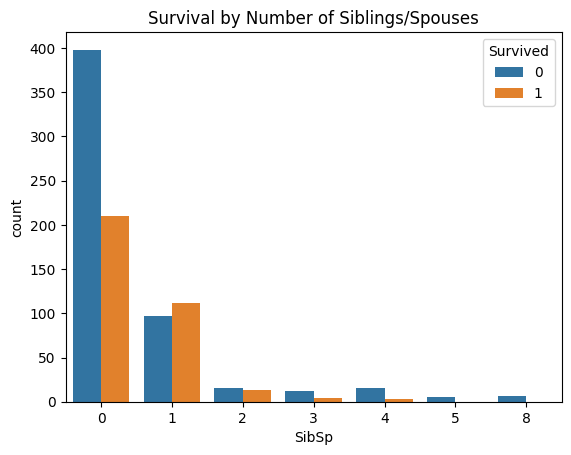

In [65]:
# Q7 : Is having more siblings or spouses aboard associated with survival?
sns.countplot(x='SibSp', hue='Survived', data=df)
plt.title('Survival by Number of Siblings/Spouses')
plt.show()

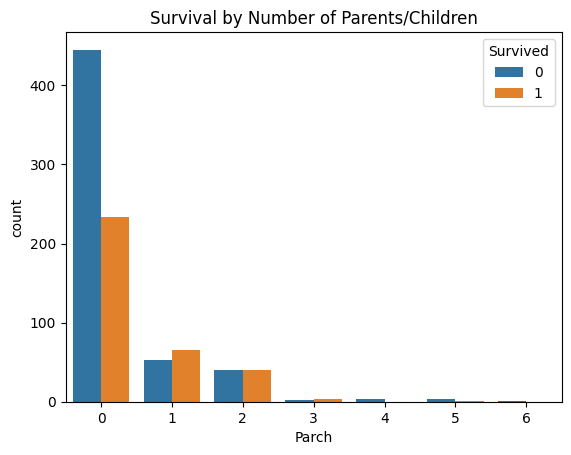

In [66]:
# Q8 : Does having parents or children aboard affect survival?
sns.countplot(x='Parch', hue='Survived', data=df)
plt.title('Survival by Number of Parents/Children')
plt.show()

# Conclusion

“From the plots and groupby numbers we can see female passengers had a much higher survival rate than males.”

“First-class passengers had higher survival rates than second and third class, suggesting socio-economic status mattered.”

“Younger passengers (children) show different survival patterns — they were often prioritized.”

“Higher Fare tends to be associated with higher survival (fare is a proxy for class/wealth).”

“Family size effect is nuanced: very large families had lower survival (harder to coordinate), while small families or those alone sometimes had different outcomes — check the FamilySize plot to interpret.”